# Feature-selectie – welke features zijn relevant?

**Datalab 3 · vervolg op de EDA**

In de EDA zagen we dat de MFCC-gemiddelden het meest onderscheidend zijn, maar ook dat de **recorder** (16 kHz of 384 kHz) de features sterk beïnvloedt. In dit notebook zoeken we systematisch uit welke features écht iets zeggen over het gedrag van de hommel.

We gebruiken **drie methoden**, die elk iets anders meten:

| Methode | Wat meet het? | Beperking |
|---|---|---|
| **ANOVA F-score** | Verschillen de *gemiddelden* van de klassen? | Kijkt naar één feature tegelijk en alleen naar lineaire verschillen |
| **Mutual information** | Hoeveel *informatie* geeft de feature over de klasse? Vangt ook niet-lineaire verbanden | Kijkt ook naar één feature tegelijk |
| **Permutation importance (Random Forest)** | Hoeveel slechter wordt een model als we de feature door elkaar husselen? | Gecorreleerde features delen hun belang |

Daarna **combineren** we de drie ranglijsten, halen we **dubbele informatie** weg (sterk gecorreleerde features) en **controleren** we met een model of de selectie net zo goed werkt als alle 64 features.

**Keuze:** we doen de selectie op de **16 kHz-opnames**, zodat het recorder-verschil niet meetelt als "onderscheidend". We kijken wel welke features vooral de recorder meten.

In [1]:
import glob
import os
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict

DATA_CSV = "../data/processed_data/bee_features_per_second.csv"
RAW_DATA_DIR = "../data/raw_data"
UITVOER_JSON = "../data/processed_data/geselecteerde_features.json"

KLASSEN = ["buzz", "flight", "noise", "radio", "voice"]
KLEUR = {"buzz": "#2a78d6", "flight": "#eb6834", "noise": "#1baf7a", "radio": "#eda100", "voice": "#e87ba4"}
GRIJS, INKT, INKT_2 = "#898781", "#0b0b0b", "#52514e"
METHODE_KLEUR = {"ANOVA": "#2a78d6", "Mutual information": "#1baf7a", "Permutation": "#eb6834"}

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "xtick.color": GRIJS, "ytick.color": GRIJS, "legend.frameon": False,
})
SEED = 42

## 1. Data laden

Dezelfde opschoning als in de EDA: spaties weghalen, **ontdubbelen** (elke rij stond er twee keer in) en de recorder per bestand bepalen.

In [2]:
df = pd.read_csv(DATA_CSV, skipinitialspace=True)
df.columns = df.columns.str.strip()
TEKST = ["start", "end", "label", "source_file"]
for k in TEKST:
    df[k] = df[k].astype("string").str.strip()
FEATURES = [k for k in df.columns if k not in TEKST]
df = df.drop_duplicates().reset_index(drop=True)
df["datum"] = pd.to_datetime(df["start"]).dt.date

# Recorder: uit de WAV-bestanden (samplerate). Lukt dat niet, dan op datum (26 mei = 16 kHz, de rest = 384 kHz).
wavs = glob.glob(os.path.join(RAW_DATA_DIR, "**", "*.WAV"), recursive=True)
if wavs:
    import soundfile as sf
    sr = {os.path.basename(p): sf.info(p).samplerate for p in wavs}
    df["recorder"] = df["source_file"].map(sr).map({16000: "16 kHz", 384000: "384 kHz"})
    print("Recorder bepaald uit de WAV-bestanden.")
else:
    df["recorder"] = np.where(df["datum"].astype(str) == "2026-05-26", "16 kHz", "384 kHz")
    print("Geen WAV-bestanden gevonden: recorder bepaald op datum.")

lab = df.dropna(subset=["label"]).copy()
lab16 = lab[lab["recorder"] == "16 kHz"].copy()
print(f"Unieke seconden: {len(df)}  |  gelabeld: {len(lab)}  |  gelabeld 16 kHz: {len(lab16)}")
print(lab16["label"].value_counts().rename("seconden (16 kHz)"))

Geen WAV-bestanden gevonden: recorder bepaald op datum.
Unieke seconden: 9198  |  gelabeld: 3716  |  gelabeld 16 kHz: 3198
label
voice     1505
radio     1216
noise      289
flight      99
buzz        89
Name: seconden (16 kHz), dtype: int64[pyarrow]


## 2. Methode 1 – ANOVA F-score

Hoe hoger de F-score, hoe meer de klassegemiddelden van elkaar verschillen ten opzichte van de spreiding binnen een klasse. We berekenen hem op de 16 kHz-opnames, en ter vergelijking met de **recorder** als groep: een feature die hoog scoort op recorder meet vooral het verschil tussen de apparaten.

In [3]:
X16, y16 = lab16[FEATURES], lab16["label"]
F_klasse, p_klasse = f_classif(X16, y16)
F_recorder, _ = f_classif(lab[FEATURES], lab["recorder"])

scores = pd.DataFrame({"ANOVA": F_klasse, "p": p_klasse, "F_recorder": F_recorder}, index=FEATURES)
print("Top 10 ANOVA (klasse, 16 kHz):")
print(scores.sort_values("ANOVA", ascending=False).head(10).round({"ANOVA": 1, "p": 4, "F_recorder": 1}))

Top 10 ANOVA (klasse, 16 kHz):
              ANOVA    p  F_recorder
mfcc_8_mean   432.9  0.0       384.8
mfcc_10_mean  192.5  0.0       806.6
mfcc_6_mean   174.6  0.0       935.4
mfcc_20_mean  167.9  0.0        19.3
mfcc_4_std    144.4  0.0        59.0
mfcc_5_std    140.8  0.0        41.0
mfcc_7_mean   139.6  0.0      1445.8
mfcc_8_std    132.3  0.0        16.9
mfcc_7_std    125.7  0.0        37.5
mfcc_9_std    114.9  0.0         1.7


## 3. Methode 2 – Mutual information

Mutual information (MI) meet hoeveel onzekerheid over de klasse verdwijnt als je de feature kent. MI = 0 betekent: de feature zegt niets. In tegenstelling tot ANOVA ziet MI ook verbanden die niet in het gemiddelde zitten (bijv. een klasse die alleen bij héél lage én héél hoge waarden voorkomt).

In [4]:
scores["Mutual information"] = mutual_info_classif(X16, y16, random_state=SEED)
print("Top 10 mutual information:")
print(scores["Mutual information"].sort_values(ascending=False).head(10).round(3))

Top 10 mutual information:
mfcc_8_mean     0.265
mfcc_10_mean    0.143
rms_mean        0.124
mfcc_20_mean    0.111
mfcc_8_std      0.102
mfcc_5_std      0.102
mfcc_7_std      0.101
mfcc_6_mean     0.100
mfcc_7_mean     0.096
mfcc_3_mean     0.093
Name: Mutual information, dtype: float64


## 4. Methode 3 – Permutation importance met een Random Forest

We trainen een Random Forest en meten per feature hoeveel de **macro-F1** daalt als we die feature willekeurig door elkaar husselen. Belangrijk:

- We splitsen **per opname** (`source_file`), zoals de EDA aanraadt. Anders zitten seconden uit dezelfde opname in train én test en lijkt het model beter dan het is.
- `class_weight="balanced"`, omdat `buzz` en `flight` zeldzaam zijn.
- We meten op de **testset** van elke fold en nemen het gemiddelde over de folds.

In [5]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
groepen = lab16["source_file"]
perm = []
for train, test in cv.split(X16, y16, groepen):
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED)
    rf.fit(X16.iloc[train], y16.iloc[train])
    r = permutation_importance(rf, X16.iloc[test], y16.iloc[test], scoring="f1_macro",
                               n_repeats=5, random_state=SEED, n_jobs=-1)
    perm.append(r.importances_mean)
scores["Permutation"] = np.mean(perm, axis=0)
print("Top 10 permutation importance (daling in macro-F1):")
print(scores["Permutation"].sort_values(ascending=False).head(10).round(4))

Top 10 permutation importance (daling in macro-F1):
mfcc_8_mean     0.0528
mfcc_3_mean     0.0516
mfcc_4_mean     0.0288
mfcc_20_mean    0.0247
mfcc_2_mean     0.0172
mfcc_5_mean     0.0167
mfcc_2_std      0.0149
mfcc_10_mean    0.0139
mfcc_1_std      0.0114
mfcc_17_mean    0.0111
Name: Permutation, dtype: float64


## 5. De drie methoden vergelijken

Elke methode heeft een andere schaal, dus we vergelijken **rangen** (1 = belangrijkste). De gecombineerde score is de gemiddelde rang over de drie methoden.

In [6]:
METHODEN = ["ANOVA", "Mutual information", "Permutation"]
rang = scores[METHODEN].rank(ascending=False)
scores["gem_rang"] = rang.mean(axis=1)
rang_recorder = scores["F_recorder"].rank(ascending=False)
scores["recorder_rang"] = rang_recorder
scores = scores.sort_values("gem_rang")

overzicht = rang.loc[scores.index].astype(int)
overzicht["gemiddelde rang"] = scores["gem_rang"].round(1)
overzicht["rang als recorder-meter"] = rang_recorder.loc[scores.index].astype(int)
print("Top 15 gecombineerd:")
print(overzicht.head(15))

Top 15 gecombineerd:
              ANOVA  Mutual information  Permutation  gemiddelde rang  \
mfcc_8_mean       1                   1            1              1.0   
mfcc_10_mean      2                   2            8              4.0   
mfcc_20_mean      4                   4            4              4.0   
mfcc_3_mean      13                  10            2              8.3   
mfcc_7_mean       7                   9           11              9.0   
mfcc_5_std        6                   6           20             10.7   
mfcc_8_std        8                   5           25             12.7   
mfcc_6_std       11                  12           18             13.7   
mfcc_13_mean     12                  16           16             14.7   
mfcc_5_mean      21                  17            6             14.7   
mfcc_6_mean       3                   8           36             15.7   
mfcc_2_mean      23                  20            5             16.0   
mfcc_4_std        5           

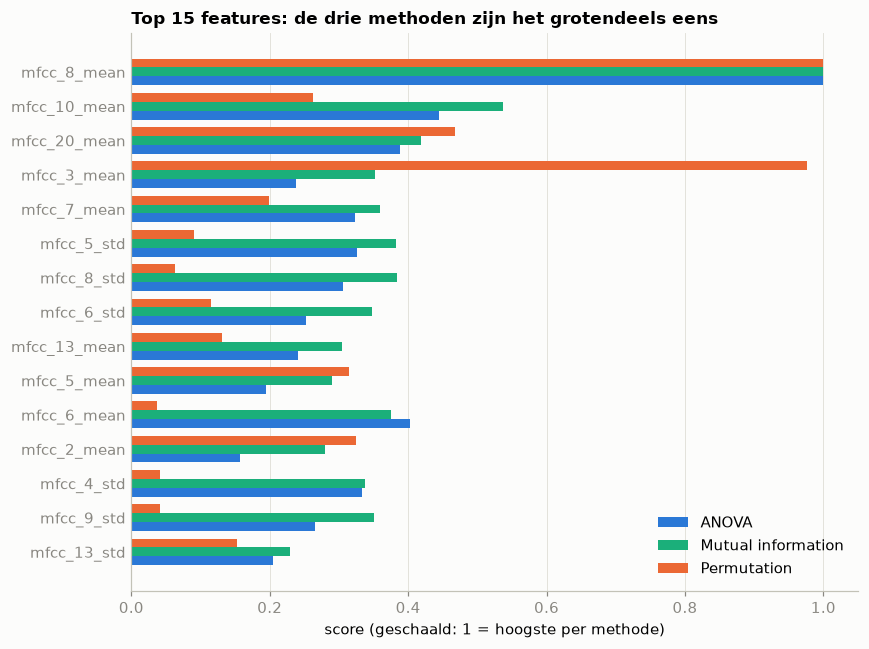

In [7]:
top = scores.head(15).index[::-1]
genorm = scores.loc[top, METHODEN] / scores[METHODEN].max()

fig, ax = plt.subplots(figsize=(8, 6))
h = 0.26
y = np.arange(len(top))
for i, m in enumerate(METHODEN):
    ax.barh(y + (i - 1) * h, genorm[m], height=h, color=METHODE_KLEUR[m], label=m)
ax.set_yticks(y, top)
ax.set_xlabel("score (geschaald: 1 = hoogste per methode)")
ax.set_title("Top 15 features: de drie methoden zijn het grotendeels eens")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

**Hoe lees je dit?** Een feature waarbij alle drie de balken lang zijn, is robuust belangrijk. Is alleen de ANOVA-balk lang, dan verschilt vooral het gemiddelde. Is alleen de permutation-balk kort terwijl de andere lang zijn, dan heeft het model die informatie ook uit een gecorreleerde feature gehaald.

## 6. Dubbele informatie verwijderen

Uit de EDA weten we dat `spectral_centroid`, `spectral_rolloff`, `zcr` en `mfcc_2` sterk samenhangen. We lopen de ranglijst van boven naar beneden af en **slaan een feature over als hij |r| > 0,85 heeft met een feature die al gekozen is**. Zo houden we per groep alleen de best scorende over.

In [8]:
DREMPEL = 0.85
corr = lab16[FEATURES].corr().abs()
gekozen, overgeslagen = [], {}
for f in scores.index:
    match = [g for g in gekozen if corr.loc[f, g] > DREMPEL]
    if match:
        overgeslagen[f] = match[0]
    else:
        gekozen.append(f)

print(f"Overgeslagen wegens correlatie > {DREMPEL}:")
for f, g in overgeslagen.items():
    print(f"  {f:28s} lijkt op {g}  (r = {corr.loc[f, g]:.2f})")

Overgeslagen wegens correlatie > 0.85:
  spectral_rolloff_mean        lijkt op mfcc_2_mean  (r = 0.93)
  spectral_centroid_mean       lijkt op mfcc_2_mean  (r = 0.88)


## 7. Controle: hoeveel features heb je nodig?

We trainen hetzelfde Random Forest met de top-*k* features (na het verwijderen van dubbele informatie) en vergelijken de **macro-F1** met alle 64 features. Ook hier splitsen we per opname.

3     0.362
5     0.427
8     0.460
10    0.461
15    0.484
20    0.518
30    0.504
Name: macro-F1, dtype: float64
Alle 64 features: 0.474


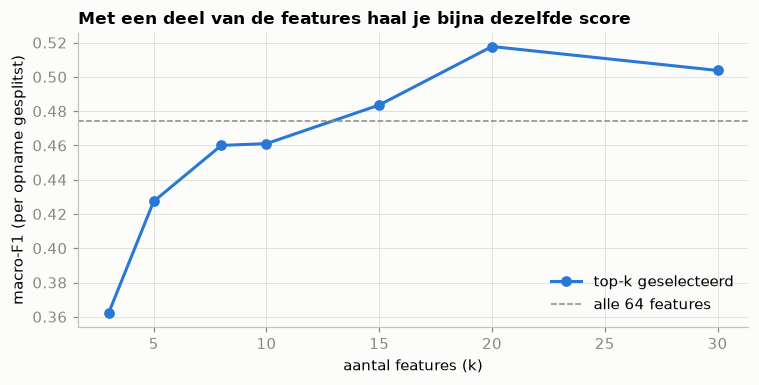

In [9]:
def macro_f1(kolommen):
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=SEED)
    voorspeld = cross_val_predict(rf, X16[kolommen], y16, cv=cv, groups=groepen)
    return f1_score(y16, voorspeld, average="macro")

ks = [k for k in [3, 5, 8, 10, 15, 20, 30] if k <= len(gekozen)]
resultaat = pd.Series({k: macro_f1(gekozen[:k]) for k in ks})
alle = macro_f1(FEATURES)
print(resultaat.round(3).rename("macro-F1"))
print(f"Alle 64 features: {alle:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(resultaat.index, resultaat.values, marker="o", color=KLEUR["buzz"], linewidth=2, label="top-k geselecteerd")
ax.axhline(alle, color=GRIJS, linestyle="--", linewidth=1, label="alle 64 features")
ax.set_xlabel("aantal features (k)")
ax.set_ylabel("macro-F1 (per opname gesplitst)")
ax.set_title("Met een deel van de features haal je bijna dezelfde score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Hoe lees je dit?** Zoek het punt waar de lijn afvlakt en dicht bij de stippellijn komt: meer features voegen daarna weinig toe. Dat aantal nemen we als selectie.

In [10]:
# Kleinste k die binnen 0,01 macro-F1 van "alle features" komt (anders de grootste k).
binnen = resultaat[resultaat >= alle - 0.01]
K = int(binnen.index.min()) if len(binnen) else int(resultaat.idxmax())
selectie = gekozen[:K]
print(f"Gekozen: top {K} features (macro-F1 {resultaat[K]:.3f} vs {alle:.3f} met alle 64)\n")
print(scores.loc[selectie, METHODEN + ["recorder_rang"]].round(3))

with open(UITVOER_JSON, "w") as fh:
    json.dump({"features": selectie, "k": K, "macro_f1_selectie": round(float(resultaat[K]), 4),
               "macro_f1_alle": round(float(alle), 4)}, fh, indent=2)
print(f"\nOpgeslagen in {UITVOER_JSON}")

Gekozen: top 15 features (macro-F1 0.484 vs 0.474 met alle 64)

                ANOVA  Mutual information  Permutation  recorder_rang
mfcc_8_mean   432.903               0.265        0.053           15.0
mfcc_10_mean  192.540               0.143        0.014           12.0
mfcc_20_mean  167.863               0.111        0.025           28.0
mfcc_3_mean   103.040               0.093        0.052            6.0
mfcc_7_mean   139.648               0.096        0.010            8.0
mfcc_5_std    140.843               0.102        0.005           23.0
mfcc_8_std    132.335               0.102        0.003           29.0
mfcc_6_std    109.524               0.092        0.006           27.0
mfcc_13_mean  104.105               0.081        0.007           18.0
mfcc_5_mean    84.161               0.077        0.017            5.0
mfcc_6_mean   174.574               0.100        0.002           11.0
mfcc_2_mean    68.095               0.074        0.017            2.0
mfcc_4_std    144.395     

## 8. Per klasse: hoe verschillen de geselecteerde features?

Boxplots van de top 4 geselecteerde features per klasse (16 kHz, zonder uitschieters).

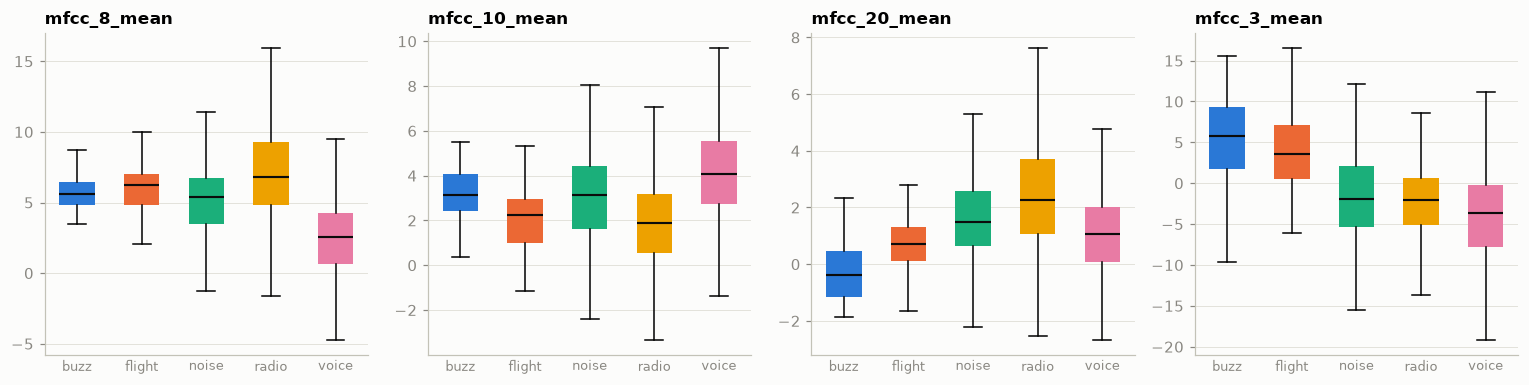

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, f in zip(axes, selectie[:4]):
    bp = ax.boxplot([lab16.loc[lab16["label"] == k, f] for k in KLASSEN], tick_labels=KLASSEN,
                    showfliers=False, patch_artist=True, widths=0.55,
                    medianprops=dict(color=INKT, linewidth=1.4))
    for vak, k in zip(bp["boxes"], KLASSEN):
        vak.set(facecolor=KLEUR[k], edgecolor="none")
    ax.set_title(f)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8.5, length=0)
plt.tight_layout()
plt.show()

## 9. Conclusie


- **Relevante features:** de lijst in `selectie` (opgeslagen in `geselecteerde_features.json`). Volgens de EDA verwachten we vooral **MFCC-gemiddelden 6, 8 en 10**.
- **Recorder-check:** features met een lage `recorder_rang` (dus hoog als recorder-meter) zijn verdacht als je later ook 384 kHz-opnames gebruikt. Die kunnen het model laten leren *welk apparaat* het was in plaats van *wat de hommel deed*.
- **Dubbele informatie:** van de groep centroid / rolloff / zcr / `mfcc_2` blijft er hooguit één of twee over.
- **Aantal:** met de gekozen *k* haal je bijna dezelfde macro-F1 als met alle 64 features: een kleiner, beter uitlegbaar model.

**Let op:** de selectie is gedaan op dezelfde data die we in stap 7 gebruiken om te controleren. Voor een eerlijke eindscore moet de selectie later **binnen** elke trainfold gebeuren (bijv. in een `Pipeline`).